# Prétraitement des images pour l'entraînement du GAN

**Plan.**
1. Chargement et détection des fichiers corrompus
2. Dimensions et ratios réels des images téléchargées
3. Filtrage des formats extrêmes
4. Recadrage : center-crop vs letterbox
5. Normalisation (tensor, plage [-1, 1])
6. `Dataset` / `DataLoader` PyTorch
7. Augmentation (optionnelle) : flip horizontal


In [1]:
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

IMAGES_DIR = Path("images")
IMG_SIZE = 128  # taille cible d'entrée du GAN
SEED = 42
random.seed(SEED)

all_files = sorted(IMAGES_DIR.rglob("*.jpg"))
print(f"{len(all_files):,} fichiers .jpg trouvés sous {IMAGES_DIR}")


158 fichiers .jpg trouvés sous images


## 1. Chargement et détection des fichiers corrompus

**Résultat.** 158/158 fichiers valides, aucun corrompu.


In [2]:
def is_valid_image(path: Path) -> bool:
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:  # verify() invalide l'objet, on rouvre pour un vrai load
            im.load()
        return True
    except Exception:
        return False

valid_files = [p for p in all_files if is_valid_image(p)]
corrupt_files = [p for p in all_files if p not in set(valid_files)]
print(f"valides   : {len(valid_files):,}")
print(f"corrompus : {len(corrupt_files):,}")


valides   : 158
corrompus : 0


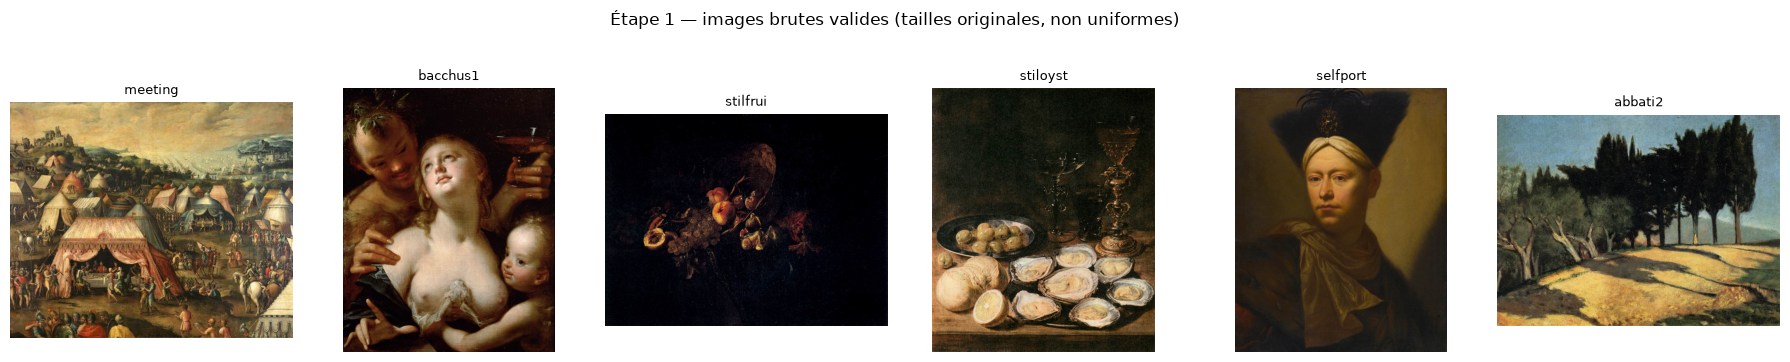

In [3]:
sample = random.sample(valid_files, min(6, len(valid_files)))
fig, axes = plt.subplots(1, len(sample), figsize=(3 * len(sample), 3.4))
for ax, p in zip(axes, sample):
    ax.imshow(Image.open(p).convert("RGB"))
    ax.set_title(p.stem, fontsize=9)
    ax.axis("off")
fig.suptitle("Étape 1 — images brutes valides (tailles originales, non uniformes)", y=1.05)
plt.tight_layout()
plt.show()


## 2. Dimensions et ratios réels des images téléchargées

**Résultat.** Ratio largeur/hauteur réel : moyenne 1,09, écart-type 0,41
(min 0,30, max 2,92) sur les fichiers téléchargés.


In [4]:
import pandas as pd

rows = []
for p in valid_files:
    with Image.open(p) as im:
        w, h = im.size
        rows.append({"path": p, "width": w, "height": h, "ratio": w / h, "mode": im.mode})
dims = pd.DataFrame(rows)
dims["ratio"].describe()


count    158.000000
mean       1.093076
std        0.412664
min        0.302118
25%        0.784670
50%        1.003591
75%        1.418211
max        2.922857
Name: ratio, dtype: float64

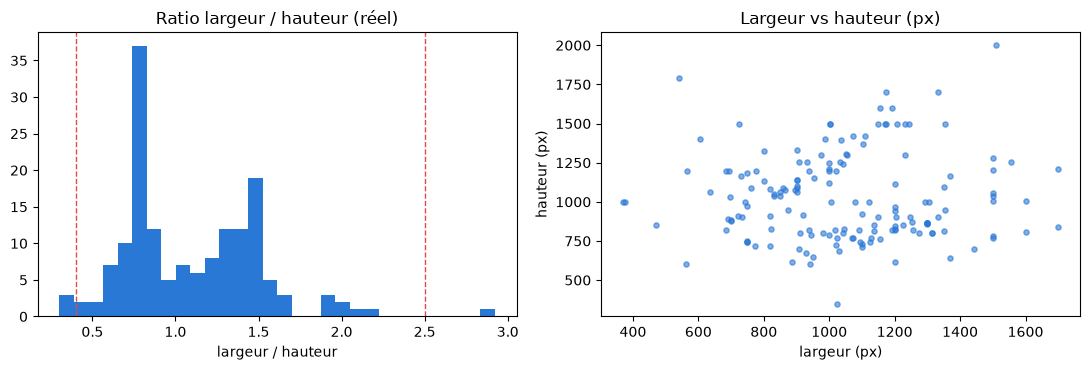

Modes de couleur rencontrés : {'RGB': 158}


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(dims["ratio"], bins=30, color="#2a78d6")
axes[0].axvline(0.4, color="#e34948", linestyle="--", linewidth=1)
axes[0].axvline(2.5, color="#e34948", linestyle="--", linewidth=1)
axes[0].set_title("Ratio largeur / hauteur (réel)")
axes[0].set_xlabel("largeur / hauteur")

axes[1].scatter(dims["width"], dims["height"], s=14, alpha=0.6, color="#2a78d6")
axes[1].set_title("Largeur vs hauteur (px)")
axes[1].set_xlabel("largeur (px)")
axes[1].set_ylabel("hauteur (px)")
plt.tight_layout()
plt.show()
print("Modes de couleur rencontrés :", dims['mode'].value_counts().to_dict())


## 3. Filtrage des formats extrêmes

**Résultat.** 154/158 images conservées (97,5 %).


conservées : 154 / 158 (97.5%)


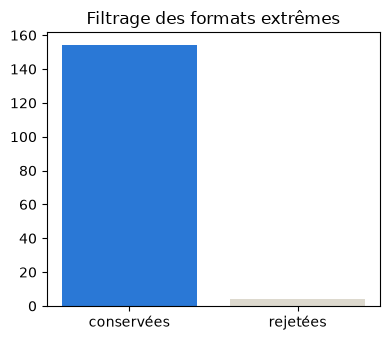

In [6]:
MIN_RATIO, MAX_RATIO = 0.4, 2.5
MIN_SIDE = 64

keep_mask = (
    (dims["ratio"].between(MIN_RATIO, MAX_RATIO))
    & (dims[["width", "height"]].min(axis=1) >= MIN_SIDE)
)
kept = dims[keep_mask]
rejected = dims[~keep_mask]

print(f"conservées : {len(kept):,} / {len(dims):,} ({len(kept) / len(dims):.1%})")

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.bar(["conservées", "rejetées"], [len(kept), len(rejected)], color=["#2a78d6", "#ddd9ce"])
ax.set_title("Filtrage des formats extrêmes")
plt.tight_layout()
plt.show()


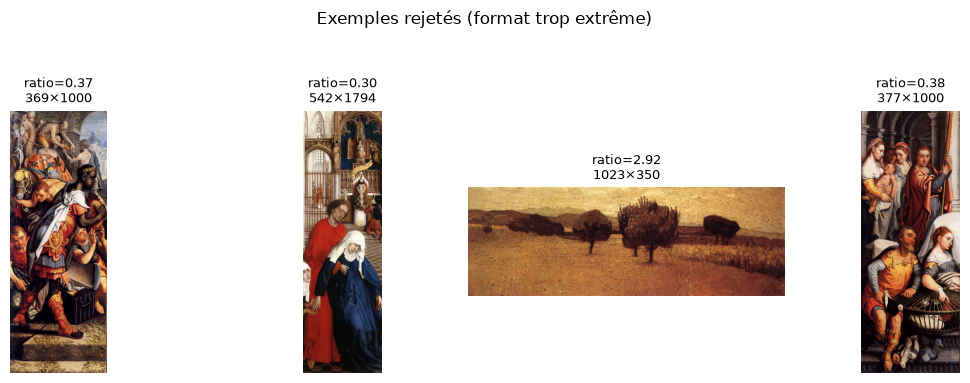

In [7]:
if len(rejected):
    sample_rej = rejected.sample(min(4, len(rejected)), random_state=SEED)
    fig, axes = plt.subplots(1, len(sample_rej), figsize=(3 * len(sample_rej), 3.6))
    axes = [axes] if len(sample_rej) == 1 else axes
    for ax, (_, row) in zip(axes, sample_rej.iterrows()):
        ax.imshow(Image.open(row["path"]).convert("RGB"))
        ax.set_title(f"ratio={row['ratio']:.2f}\n{row['width']}×{row['height']}", fontsize=9)
        ax.axis("off")
    fig.suptitle("Exemples rejetés (format trop extrême)", y=1.05)
    plt.tight_layout()
    plt.show()
else:
    print("Aucune image rejetée dans cet échantillon.")


## 4. Recadrage : center-crop vs letterbox

**Résultat.** Center-crop retenu : les formats extrêmes étant déjà filtrés,
il perd peu de contenu et évite les bordures artificielles du letterbox.


In [8]:
def center_crop_resize(img: Image.Image, size: int) -> Image.Image:
    w, h = img.size
    side = min(w, h)
    left, top = (w - side) // 2, (h - side) // 2
    return img.crop((left, top, left + side, top + side)).resize((size, size), Image.BICUBIC)


def letterbox_resize(img: Image.Image, size: int, fill=(0, 0, 0)) -> Image.Image:
    w, h = img.size
    scale = size / max(w, h)
    new_w, new_h = round(w * scale), round(h * scale)
    resized = img.resize((new_w, new_h), Image.BICUBIC)
    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(resized, ((size - new_w) // 2, (size - new_h) // 2))
    return canvas


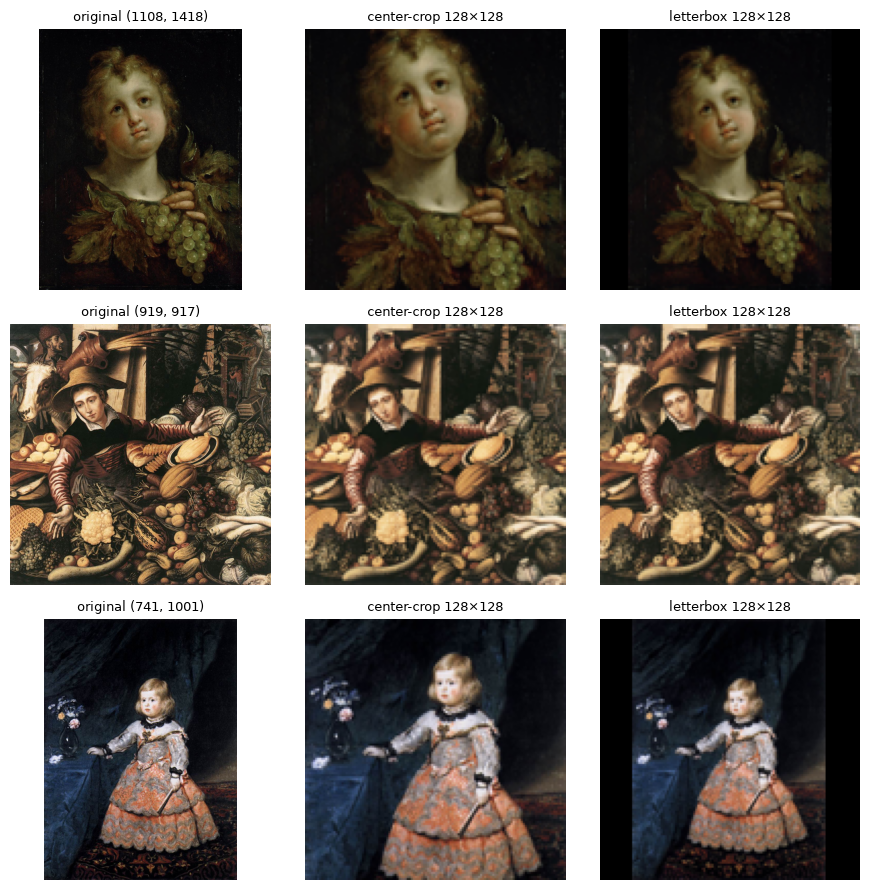

In [9]:
sample_paths = kept.sample(min(3, len(kept)), random_state=SEED)["path"].tolist()
fig, axes = plt.subplots(len(sample_paths), 3, figsize=(9, 3 * len(sample_paths)))
axes = axes.reshape(len(sample_paths), 3)
for row_ax, p in zip(axes, sample_paths):
    original = Image.open(p).convert("RGB")
    row_ax[0].imshow(original)
    row_ax[0].set_title(f"original {original.size}", fontsize=9)
    row_ax[1].imshow(center_crop_resize(original, IMG_SIZE))
    row_ax[1].set_title(f"center-crop {IMG_SIZE}×{IMG_SIZE}", fontsize=9)
    row_ax[2].imshow(letterbox_resize(original, IMG_SIZE))
    row_ax[2].set_title(f"letterbox {IMG_SIZE}×{IMG_SIZE}", fontsize=9)
    for ax in row_ax:
        ax.axis("off")
plt.tight_layout()
plt.show()


## 5. Normalisation

**Résultat.** Pipeline validé : RGB → center-crop/resize → tensor `[0, 1]`
→ normalisation `[-1, 1]`.


shape : (3, 128, 128) | min/max après normalisation : -0.9764705896377563 0.545098066329956


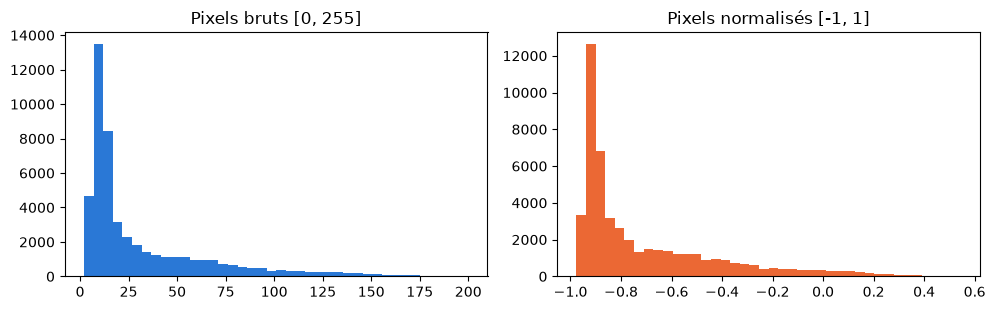

In [11]:
import torch
from torchvision import transforms

transform = transforms.Compose([
    transforms.Lambda(lambda im: im.convert("RGB")),
    transforms.Lambda(lambda im: center_crop_resize(im, IMG_SIZE)),
    transforms.ToTensor(),                              # [0, 1]
    transforms.Normalize([0.5] * 3, [0.5] * 3),          # -> [-1, 1]
])

demo_img = Image.open(sample_paths[0])
tensor = transform(demo_img)
print("shape :", tuple(tensor.shape), "| min/max après normalisation :", tensor.min().item(), tensor.max().item())

raw = np.asarray(demo_img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))).flatten()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(raw, bins=40, color="#2a78d6")
axes[0].set_title("Pixels bruts [0, 255]")
axes[1].hist(tensor.numpy().flatten(), bins=40, color="#eb6834")
axes[1].set_title("Pixels normalisés [-1, 1]")
plt.tight_layout()
plt.show()


## 6. `Dataset` / `DataLoader` PyTorch

**Résultat.** `Dataset` opérationnel : 154 images, 10 batches de 16.


In [12]:
from torch.utils.data import Dataset, DataLoader


class PaintingsDataset(Dataset):
    def __init__(self, paths, size=IMG_SIZE):
        self.paths = list(paths)
        self.transform = transforms.Compose([
            transforms.Lambda(lambda im: im.convert("RGB")),
            transforms.Lambda(lambda im: center_crop_resize(im, size)),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * 3, [0.5] * 3),
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            with Image.open(self.paths[idx]) as im:
                return self.transform(im)
        except Exception:
            return self.__getitem__((idx + 1) % len(self))


dataset = PaintingsDataset(kept["path"])
loader = DataLoader(dataset, batch_size=16, shuffle=True, num_workers=0)
print(f"Dataset prêt : {len(dataset):,} images, batch_size=16, {len(loader)} batches")


Dataset prêt : 154 images, batch_size=16, 10 batches


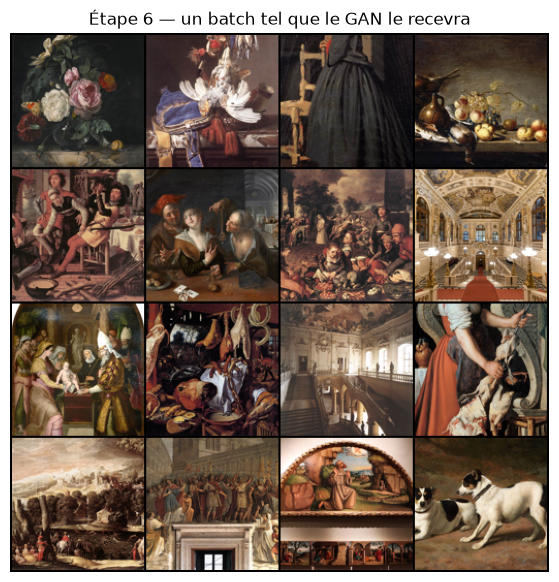

In [13]:
from torchvision.utils import make_grid

batch = next(iter(loader))
grid = make_grid(batch, nrow=4, normalize=True, value_range=(-1, 1))

plt.figure(figsize=(7, 7))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Étape 6 — un batch tel que le GAN le recevra")
plt.show()


## 7. Augmentation (optionnelle) : flip horizontal

**Résultat.** Flip horizontal implémenté et illustré ; laissé optionnel
(réserve sur les conventions picturales : signatures, sens de lecture).


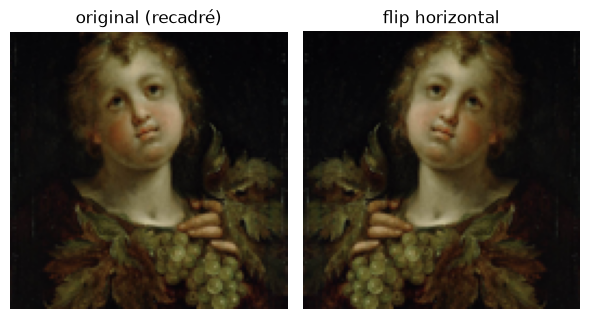

In [14]:
demo = Image.open(sample_paths[0]).convert("RGB")
cropped = center_crop_resize(demo, IMG_SIZE)
flipped = cropped.transpose(Image.FLIP_LEFT_RIGHT)

fig, axes = plt.subplots(1, 2, figsize=(6, 3.4))
axes[0].imshow(cropped); axes[0].set_title("original (recadré)"); axes[0].axis("off")
axes[1].imshow(flipped); axes[1].set_title("flip horizontal"); axes[1].axis("off")
plt.tight_layout()
plt.show()


## Résumé

| Étape | Résultat |
|---|---|
| Fichiers trouvés | voir cellule 1 |
| Valides / corrompus | voir étape 1 |
| Conservés après filtrage de ratio/taille | voir étape 3 |
| Taille finale | 128×128, RGB, `[-1, 1]` |
